# Streamlit Dashboard project Moretti Paul - Road Accidents in France (2024)

## Project Objective

This project aims to analyze road traffic accidents in France in 2024, identify temporal and geographical patterns, and explore the circumstances associated with accidents.

The analysis will be used to develop an interactive Streamlit dashboard focused on data storytelling.

## 1. Load Dataset

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
from pathlib import Path

In [5]:
data_path = Path("data/caract-2024.csv")

df = pd.read_csv(
    data_path,
    sep=";",
    encoding="utf-8",
    low_memory=False
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (54402, 15)


,Num_Acc,jour,mois,an,hrmn,lum,dep,com,agg,int,atm,col,adr,lat,long
0,202400000001,25,3,2024,07:40,2,70,70285,1,1,5,1,D438,"47,56277000","6,75832000"
1,202400000002,20,3,2024,15:05,1,21,21054,2,3,7,6,HOTEL DIEU (RUE DE L'),"47,02109000","4,83755000"
2,202400000003,22,3,2024,19:30,2,15,15012,1,1,1,6,Allée des Tilleuls,"44,90238400","2,49641800"
3,202400000004,24,3,2024,17:50,1,14,14118,2,3,7,3,128 Rue d'Authie,"49,19166000","-0,39851000"
4,202400000005,25,3,2024,19:35,5,13,13106,1,3,2,5,BEDOULE (CHEMIN DE LA),"43,39000000","5,35000000"


## 2. Data Exploration

In [6]:
print("DATASET INFORMATION")
df.info()

print("\nMISSING VALUES")
missing = pd.DataFrame({
    "Missing": df.isna().sum(),
    "Percentage (%)": (df.isna().mean() * 100).round(2)
})

display(missing)

print("\nDUPLICATES")
print("Duplicated rows:", df.duplicated().sum())
print("Duplicated accident IDs:", df["Num_Acc"].duplicated().sum())

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54402 entries, 0 to 54401
Data columns (total 15 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Num_Acc  54402 non-null  int64 
 1   jour     54402 non-null  int64 
 2   mois     54402 non-null  int64 
 3   an       54402 non-null  int64 
 4   hrmn     54402 non-null  object
 5   lum      54402 non-null  int64 
 6   dep      54402 non-null  object
 7   com      54402 non-null  object
 8   agg      54402 non-null  int64 
 9   int      54402 non-null  int64 
 10  atm      54402 non-null  int64 
 11  col      54402 non-null  int64 
 12  adr      52092 non-null  object
 13  lat      54402 non-null  object
 14  long     54402 non-null  object
dtypes: int64(9), object(6)
memory usage: 6.2+ MB

MISSING VALUES


,Missing,Percentage (%)
Num_Acc,0,0.00
jour,0,0.00
mois,0,0.00
an,0,0.00
hrmn,0,0.00
lum,0,0.00
dep,0,0.00
com,0,0.00
agg,0,0.00
int,0,0.00



DUPLICATES
Duplicated rows: 0
Duplicated accident IDs: 0


In [7]:
# Check categorical values
categorical_cols = ["lum", "agg", "int", "atm", "col"]

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).sort_index())

# Check geographical coordinates
for col in ["lat", "long"]:
    coordinates = pd.to_numeric(
        df[col].astype(str).str.replace(",", ".", regex=False),
        errors="coerce"
    )

    print(f"\n{col}:")
    print("Invalid or missing values:", coordinates.isna().sum())
    print("Minimum:", coordinates.min())
    print("Maximum:", coordinates.max())

# Check dates and times
print("\nMonths:", sorted(df["mois"].unique()))
print("Years:", sorted(df["an"].unique()))
print(
    "Invalid time formats:",
    (~df["hrmn"].astype(str).str.fullmatch(r"\d{2}:\d{2}")).sum()
)


lum:
lum
1    35580
2     3599
3     6101
4      623
5     8499
Name: count, dtype: int64

agg:
agg
1    20392
2    34010
Name: count, dtype: int64

int:
int
1    34589
2     6289
3     6451
4     1048
5      263
6     2717
7      453
8      138
9     2454
Name: count, dtype: int64

atm:
atm
1    41802
2     6779
3     1449
4      233
5      529
6      169
7      817
8     2374
9      250
Name: count, dtype: int64

col:
col
-1        6
 1     6057
 2     7162
 3    16371
 4     1821
 5     1554
 6    15968
 7     5463
Name: count, dtype: int64

lat:
Invalid or missing values: 0
Minimum: -22.433239
Maximum: 51.07874

long:
Invalid or missing values: 0
Minimum: -178.094387
Maximum: 167.863219

Months: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]
Years: [np.int64(2024)]
Invalid time formats: 0


## 3. Data Cleaning & Preprocessing

In [8]:
# Create a working copy
df_clean = df.copy()

# Convert geographical coordinates
for col in ["lat", "long"]:
    df_clean[col] = pd.to_numeric(
        df_clean[col].astype(str).str.replace(",", ".", regex=False),
        errors="coerce"
    )

# Create date column
df_clean["date"] = pd.to_datetime(
    df_clean[["an", "mois", "jour"]].rename(
        columns={"an": "year", "mois": "month", "jour": "day"}
    ),
    errors="coerce"
)

# Extract hour
df_clean["hour"] = pd.to_numeric(
    df_clean["hrmn"].str.split(":").str[0],
    errors="coerce"
)

# Extract day of week
df_clean["day_of_week"] = df_clean["date"].dt.day_name()

# Handle unknown collision codes
df_clean["col"] = df_clean["col"].replace(-1, np.nan)

# Validation
print("Cleaned dataset shape:", df_clean.shape)
print("Invalid dates:", df_clean["date"].isna().sum())
print("Invalid hours:", df_clean["hour"].isna().sum())
print("Unknown collisions:", df_clean["col"].isna().sum())

display(df_clean.head())

Cleaned dataset shape: (54402, 18)
Invalid dates: 0
Invalid hours: 0
Unknown collisions: 6


,Num_Acc,jour,mois,an,hrmn,lum,dep,com,agg,int,atm,col,adr,lat,long,date,hour,day_of_week
0,202400000001,25,3,2024,07:40,2,70,70285,1,1,5,1.0,D438,47.562770,6.758320,2024-03-25,7,Monday
1,202400000002,20,3,2024,15:05,1,21,21054,2,3,7,6.0,HOTEL DIEU (RUE DE L'),47.021090,4.837550,2024-03-20,15,Wednesday
2,202400000003,22,3,2024,19:30,2,15,15012,1,1,1,6.0,Allée des Tilleuls,44.902384,2.496418,2024-03-22,19,Friday
3,202400000004,24,3,2024,17:50,1,14,14118,2,3,7,3.0,128 Rue d'Authie,49.191660,-0.398510,2024-03-24,17,Sunday
4,202400000005,25,3,2024,19:35,5,13,13106,1,3,2,5.0,BEDOULE (CHEMIN DE LA),43.390000,5.350000,2024-03-25,19,Monday


We need to convert the numerical codes into meaningful categories according to the official BAAC nomenclature to make the dataset easier to understand and analyze.

In [10]:
lum_labels = {
    1: "Daylight",
    2: "Dawn / Dusk",
    3: "Night - No street lighting",
    4: "Night - Street lights off",
    5: "Night - Street lights on"
}

agg_labels = {
    1: "Outside urban area",
    2: "Urban area"
}

atm_labels = {
    1: "Normal",
    2: "Light rain",
    3: "Heavy rain",
    4: "Snow / Hail",
    5: "Fog / Smoke",
    6: "Strong wind / Storm",
    7: "Glare",
    8: "Cloudy",
    9: "Other"
}

int_labels = {
    1: "Outside intersection",
    2: "Crossroads (X)",
    3: "T-junction",
    4: "Y-junction",
    5: "Multiple branches",
    6: "Roundabout",
    7: "Square",
    8: "Level crossing",
    9: "Other intersection"
}

col_labels = {
    1: "Two vehicles - Head-on",
    2: "Two vehicles - Rear-end",
    3: "Two vehicles - Side collision",
    4: "Three or more - Chain collision",
    5: "Three or more - Multiple collision",
    6: "Other collision",
    7: "No collision"
}

df_clean["luminosity"] = df_clean["lum"].map(lum_labels)
df_clean["area_type"] = df_clean["agg"].map(agg_labels)
df_clean["weather"] = df_clean["atm"].map(atm_labels)
df_clean["intersection"] = df_clean["int"].map(int_labels)
df_clean["collision_type"] = df_clean["col"].map(col_labels).fillna("Unknown")

display(df_clean[
    ["date", "hour", "luminosity", "area_type",
     "weather", "intersection", "collision_type"]
].head())

print("\nUnmapped values:")
for col in ["luminosity", "area_type", "weather", "intersection"]:
    print(f"{col}: {df_clean[col].isna().sum()}")

print("Unknown collisions:",
      (df_clean["collision_type"] == "Unknown").sum())

,date,hour,luminosity,area_type,weather,intersection,collision_type
0,2024-03-25,7,Dawn / Dusk,Outside urban area,Fog / Smoke,Outside intersection,Two vehicles - Head-on
1,2024-03-20,15,Daylight,Urban area,Glare,T-junction,Other collision
2,2024-03-22,19,Dawn / Dusk,Outside urban area,Normal,Outside intersection,Other collision
3,2024-03-24,17,Daylight,Urban area,Glare,T-junction,Two vehicles - Side collision
4,2024-03-25,19,Night - Street lights on,Outside urban area,Light rain,T-junction,Three or more - Multiple collision



Unmapped values:
luminosity: 0
area_type: 0
weather: 0
intersection: 0
Unknown collisions: 6


## 4. Exploratory Data Analysis

In this section, we explore the dataset to identify patterns and trends in road accidents across France in 2024. We focus on temporal variations, environmental conditions, and geographical distributions for our Streamlit dashboard.

### 4.1 Monthly Accident Distribution

In [11]:
monthly_accidents = (
    df_clean.groupby("mois")
    .size()
    .reset_index(name="Accidents")
    .rename(columns={"mois": "Month"})
)

display(monthly_accidents)

highest = monthly_accidents.loc[
    monthly_accidents["Accidents"].idxmax()
]

lowest = monthly_accidents.loc[
    monthly_accidents["Accidents"].idxmin()
]

print(f"Highest month: {int(highest['Month'])} "
      f"({int(highest['Accidents'])} accidents)")

print(f"Lowest month: {int(lowest['Month'])} "
      f"({int(lowest['Accidents'])} accidents)")

,Month,Accidents
0,1,4069
1,2,3792
2,3,4370
3,4,4586
4,5,4517
5,6,5135
6,7,5209
7,8,4450
8,9,4620
9,10,4803


Highest month: 7 (5209 accidents)
Lowest month: 2 (3792 accidents)


### Visualisation Map

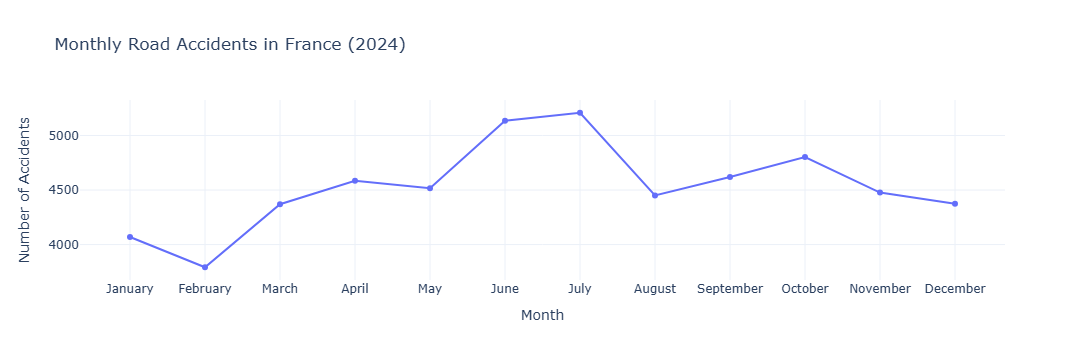

In [52]:
import calendar

monthly_accidents["Month_Name"] = monthly_accidents["Month"].apply(
    lambda x: calendar.month_name[x]
)

fig = px.line(
    monthly_accidents,
    x="Month_Name",
    y="Accidents",
    markers=True,
    title="Monthly Road Accidents in France (2024)",
    labels={
        "Month_Name": "Month",
        "Accidents": "Number of Accidents"
    },
    category_orders={
        "Month_Name": list(calendar.month_name)[1:]
    }
)

fig.update_layout(
    template="plotly_white",
    hovermode="x unified"
)

fig.show()

The monthly distribution shows that July recorded the highest number of road accidents (5,209), while February recorded the lowest (3,792). Accidents generally increased during the first half of the year, peaked in June and July, and decreased in August.

These variations may be influenced by seasonal mobility patterns and traffic volume. However, the dataset does not provide sufficient information to establish a direct causal relationship. Febuary has fewer days than other months, which may influence the total number of accidents recorded. It could be interesting to analyse the average number of accidents per day t

In [17]:
monthly_accidents["Days"] = monthly_accidents["Month"].apply(
    lambda month: calendar.monthrange(2024, month)[1]
)

monthly_accidents["Daily_Average"] = (
    monthly_accidents["Accidents"] / monthly_accidents["Days"]
).round(2)

display(
    monthly_accidents
    .sort_values("Month")
    [["Month_Name", "Accidents", "Days", "Daily_Average"]]
)

,Month_Name,Accidents,Days,Daily_Average
0,January,4069,31,131.26
1,February,3792,29,130.76
2,March,4370,31,140.97
3,April,4586,30,152.87
4,May,4517,31,145.71
5,June,5135,30,171.17
6,July,5209,31,168.03
7,August,4450,31,143.55
8,September,4620,30,154.00
9,October,4803,31,154.94


After normalizing the number of accidents by the number of days in each month, February remains the month with the lowest daily average (130.76 accidents/day).

However, June becomes the month with the highest daily average (171.17 accidents/day), surpassing July (168.03 accidents/day).

This demonstrates that comparing raw accident counts can be misleading when periods have different durations.

### 4.2 Hourly distribution of road accidents

In [13]:
hourly_accidents = (
    df_clean.groupby("hour")
    .size()
    .reset_index(name="Accidents")
    .sort_values("hour")
)

display(hourly_accidents)

highest_hour = hourly_accidents.loc[
    hourly_accidents["Accidents"].idxmax()
]

lowest_hour = hourly_accidents.loc[
    hourly_accidents["Accidents"].idxmin()
]

print(f"Highest hour: {int(highest_hour['hour'])}:00 "
      f"({int(highest_hour['Accidents'])} accidents)")

print(f"Lowest hour: {int(lowest_hour['hour'])}:00 "
      f"({int(lowest_hour['Accidents'])} accidents)")

,hour,Accidents
0,0,1168
1,1,955
2,2,807
3,3,602
4,4,630
5,5,886
6,6,1218
7,7,2442
8,8,3161
9,9,2673


Highest hour: 17:00 (4607 accidents)
Lowest hour: 3:00 (602 accidents)


### Visualisation Map

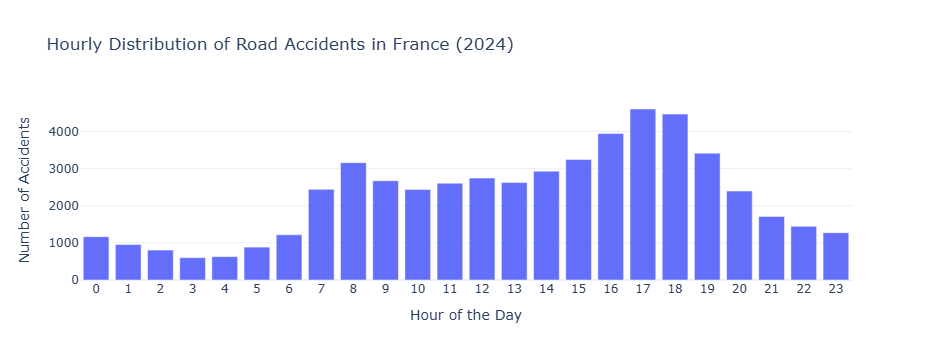

In [14]:
fig = px.bar(
    hourly_accidents,
    x="hour",
    y="Accidents",
    title="Hourly Distribution of Road Accidents in France (2024)",
    labels={
        "hour": "Hour of the Day",
        "Accidents": "Number of Accidents"
    }
)

fig.update_layout(
    template="plotly_white",
    xaxis=dict(
        tickmode="linear",
        tick0=0,
        dtick=1
    )
)

fig.show()

The hourly distribution shows two main peaks in road accidents: one around 8 AM and a more significant one between 4 PM and 7 PM.

The highest number of accidents occurs at 5 PM (4,607), while the lowest occurs at 3 AM (602).

These patterns may be associated with commuting hours and higher traffic volumes.

### 4.3 Environnemental Conditions

1. Distribution of accidents by luminosity

In [18]:
luminosity_accidents = (
    df_clean.groupby("luminosity")
    .size()
    .reset_index(name="Accidents")
    .sort_values("Accidents", ascending=False)
)

luminosity_accidents["Percentage"] = (
    luminosity_accidents["Accidents"] / len(df_clean) * 100
).round(2)

display(luminosity_accidents)

,luminosity,Accidents,Percentage
1,Daylight,35580,65.40
4,Night - Street lights on,8499,15.62
2,Night - No street lighting,6101,11.21
0,Dawn / Dusk,3599,6.62
3,Night - Street lights off,623,1.15


Visualization map

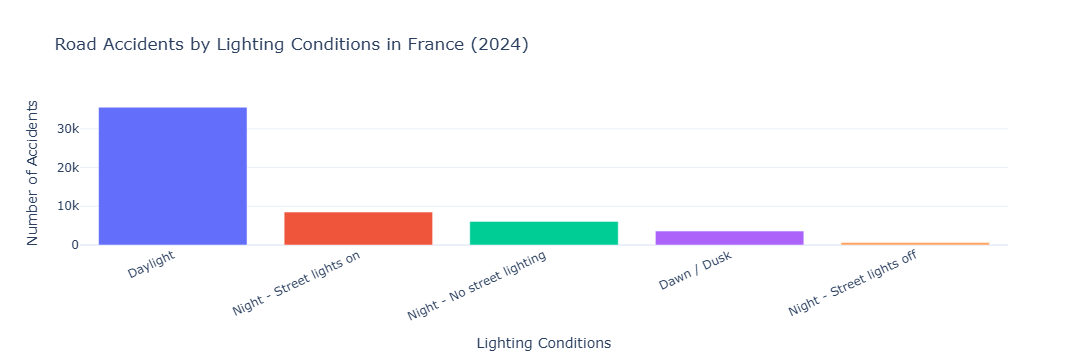

In [19]:
fig = px.bar(
    luminosity_accidents,
    x="luminosity",
    y="Accidents",
    color="luminosity",
    title="Road Accidents by Lighting Conditions in France (2024)",
    labels={
        "luminosity": "Lighting Conditions",
        "Accidents": "Number of Accidents"
    },
    hover_data=["Percentage"]
)

fig.update_layout(
    template="plotly_white",
    showlegend=False,
    xaxis_tickangle=-25
)

fig.show()

2. Distribution of accidents by weather conditions

In [20]:
weather_accidents = (
    df_clean.groupby("weather")
    .size()
    .reset_index(name="Accidents")
    .sort_values("Accidents", ascending=False)
)

weather_accidents["Percentage"] = (
    weather_accidents["Accidents"] / len(df_clean) * 100
).round(2)

display(weather_accidents)

,weather,Accidents,Percentage
5,Normal,41802,76.84
4,Light rain,6779,12.46
0,Cloudy,2374,4.36
3,Heavy rain,1449,2.66
2,Glare,817,1.50
1,Fog / Smoke,529,0.97
6,Other,250,0.46
7,Snow / Hail,233,0.43
8,Strong wind / Storm,169,0.31


Visualization map

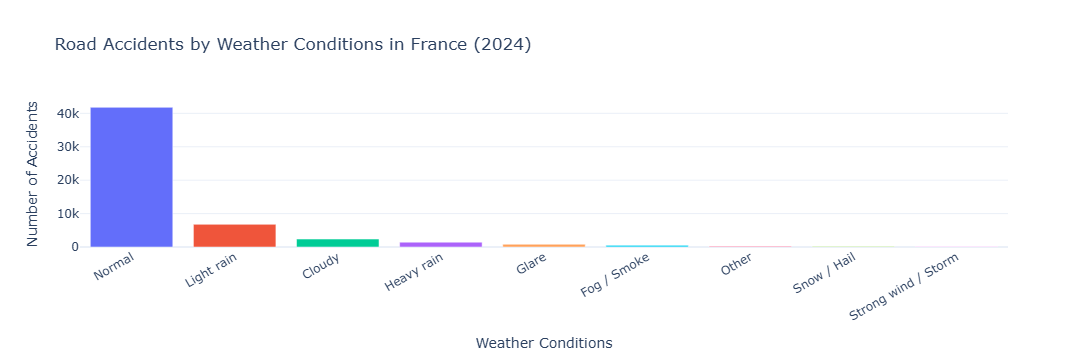

In [21]:
fig = px.bar(
    weather_accidents,
    x="weather",
    y="Accidents",
    color="weather",
    title="Road Accidents by Weather Conditions in France (2024)",
    labels={
        "weather": "Weather Conditions",
        "Accidents": "Number of Accidents"
    },
    hover_data=["Percentage"]
)

fig.update_layout(
    template="plotly_white",
    showlegend=False,
    xaxis_tickangle=-30
)

fig.show()

Most recorded road accidents occurred during daylight (65.40%) and under normal weather conditions (76.84%).

This may partly reflect higher traffic volumes during favorable conditions. Another possible explanation is that drivers adapt their behavior and become more cautious when weather conditions deteriorate.

Furthermore, June and July recorded some of the highest accident frequencies of the year, which raises questions about the relationship between seasonal mobility and weather conditions.

3. Distribution of accidents by area type

In [22]:
area_accidents = (
    df_clean.groupby("area_type")
    .size()
    .reset_index(name="Accidents")
    .sort_values("Accidents", ascending=False)
)

area_accidents["Percentage"] = (
    area_accidents["Accidents"] / len(df_clean) * 100
).round(2)

display(area_accidents)

,area_type,Accidents,Percentage
1,Urban area,34010,62.52
0,Outside urban area,20392,37.48


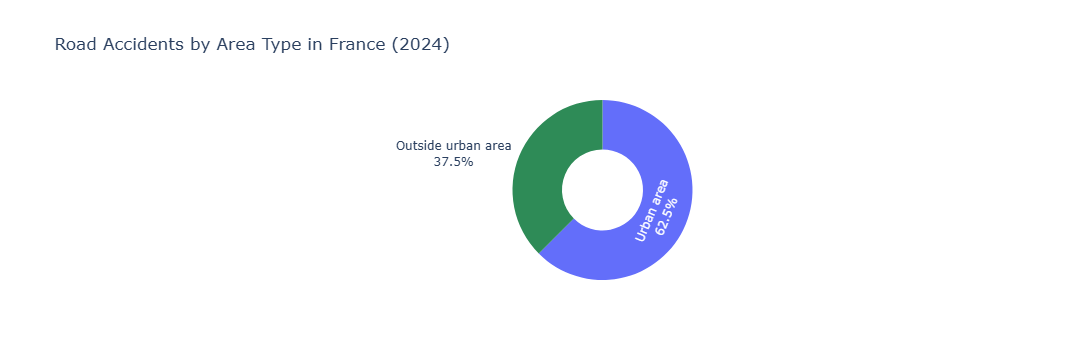

In [24]:
fig = px.pie(
    area_accidents,
    names="area_type",
    values="Accidents",
    hole=0.45,
    title="Road Accidents by Area Type in France (2024)",
    color="area_type",
    color_discrete_map={
        "Urban area": "#636EFA",
        "Outside urban area": "#2E8B57"
    }
)

fig.update_traces(
    textinfo="percent+label",
    hovertemplate="%{label}<br>Accidents: %{value:,}<br>Share: %{percent}<extra></extra>"
)

fig.update_layout(
    template="plotly_white",
    showlegend=False
)

fig.show()

In 2024, 62.52% of recorded road accidents occurred in urban areas, compared to 37.48% outside urban areas. This indicates a higher concentration of recorded accidents in urban environments, potentially associated with traffic density and the number of road users.

### 4.4 Geographical Distribution

In this part, we explore the geographical distribution of recorded road accidents in France in 2024. The objective is to identify spatial patterns and compare accidents occurring in urban and non-urban areas.

In [25]:
map_df = df_clean[
    ["lat", "long", "area_type"]
].dropna().copy()

map_df = map_df[
    map_df["lat"].between(-90, 90) &
    map_df["long"].between(-180, 180)
]

print("Total accidents in dataset:", len(df_clean))
print("Accidents with valid coordinates:", len(map_df))
print("Excluded accidents:", len(df_clean) - len(map_df))

display(map_df.head())

Total accidents in dataset: 54402
Accidents with valid coordinates: 54402
Excluded accidents: 0


,lat,long,area_type
0,47.562770,6.758320,Outside urban area
1,47.021090,4.837550,Urban area
2,44.902384,2.496418,Outside urban area
3,49.191660,-0.398510,Urban area
4,43.390000,5.350000,Outside urban area


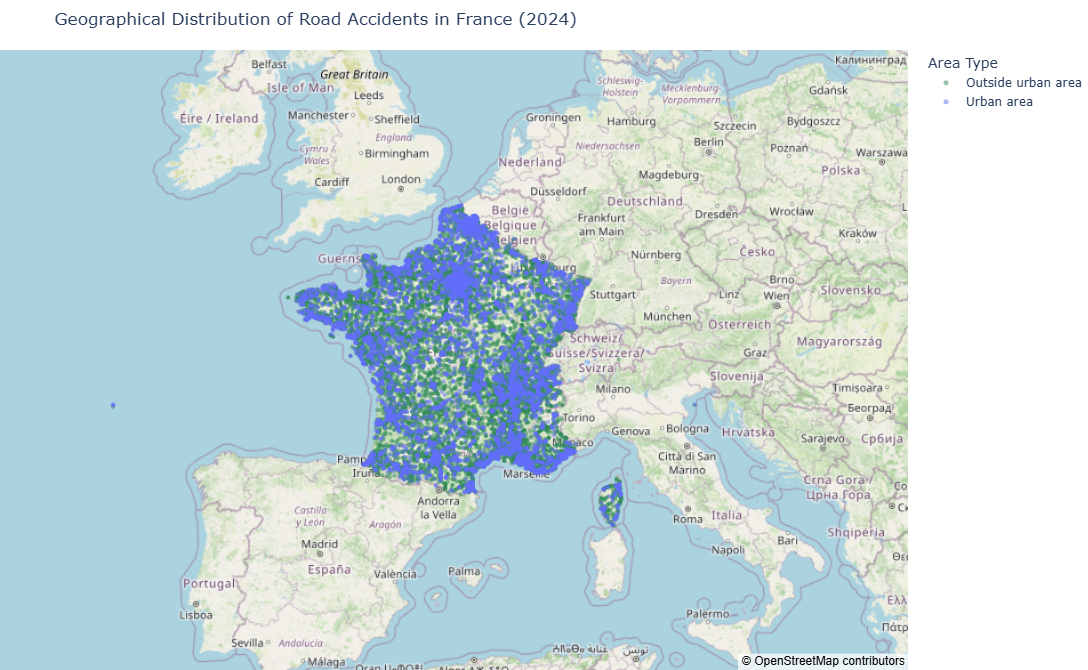

In [26]:
fig = px.scatter_map(
    map_df,
    lat="lat",
    lon="long",
    color="area_type",
    title="Geographical Distribution of Road Accidents in France (2024)",
    color_discrete_map={
        "Urban area": "#636EFA",
        "Outside urban area": "#2E8B57"
    },
    hover_data={
        "lat": ":.4f",
        "long": ":.4f",
        "area_type": False
    },
    zoom=4,
    center={"lat": 46.6, "lon": 2.2},
    height=650
)

fig.update_traces(
    marker={"size": 5, "opacity": 0.5}
)

fig.update_layout(
    map_style="open-street-map",
    template="plotly_white",
    legend_title="Area Type",
    margin={"r": 0, "t": 50, "l": 0, "b": 0}
)

fig.show()

The geographical distribution shows a high concentration of recorded road accidents around major urban areas, particularly Paris, Lyon, Marseille, and Lille.

Accidents outside urban areas appear more geographically dispersed, while urban accidents form denser clusters.

## 5. Streamlit Dashboard Development

In [27]:
output_path = Path("data/accidents_2024_clean.csv")

df_clean.to_csv(
    output_path,
    index=False,
    encoding="utf-8"
)

print("Cleaned dataset exported successfully!")
print("File:", output_path)
print("Shape:", df_clean.shape)

Cleaned dataset exported successfully!
File: data\accidents_2024_clean.csv
Shape: (54402, 23)


In [1]:
%%writefile app.py
import streamlit as st
import pandas as pd
from pathlib import Path
import plotly.express as px

st.set_page_config(
    page_title="Road Accidents in France | 2024",
    page_icon="🚗",
    layout="wide"
)

@st.cache_data
def load_data():
    path = Path(__file__).parent / "data" / "accidents_2024_clean.csv"
    data = pd.read_csv(path, parse_dates=["date"])
    return data

df = load_data()

# Dashboard header
st.title("Road Accidents in France — 2024")

st.markdown(
    """
    ### Understanding when, where, and under which conditions accidents occur

    This interactive dashboard explores **54,402 recorded road accidents**
    in France during 2024, using official French road accident data.

    The objective is to identify temporal, environmental, and geographical
    patterns while highlighting the limitations of accident frequency data.
    """
)

st.caption("Source: French Ministry of the Interior — BAAC 2024")

# ---------------------------------------
# DASHBOARD NAVIGATION
# ---------------------------------------

with st.sidebar:

    # EFREI Logo
    logo_path = Path(__file__).parent / "assets" / "Efrei_Logo_2026.svg"

    if logo_path.exists():
        st.image(str(logo_path), width=180)

    st.divider()

    st.header("Navigation")

    st.markdown("""
    - [Overview](#road-accidents-in-france-2024)
    - [Temporal Analysis](#temporal-analysis)
    - [Environmental Analysis](#environmental-analysis)
    - [Geographical Analysis](#geographical-analysis)
    - [Data Quality](#data-quality-and-limitations)
    - [Conclusions](#key-findings-and-conclusions)
    """)

    st.divider()

# Sidebar filters
st.sidebar.header("Dashboard Filters")

# Month dropdown filter
month_options = {
    "All months": 0,
    "January": 1,
    "February": 2,
    "March": 3,
    "April": 4,
    "May": 5,
    "June": 6,
    "July": 7,
    "August": 8,
    "September": 9,
    "October": 10,
    "November": 11,
    "December": 12
}

selected_month = st.sidebar.selectbox(
    "Select month",
    options=list(month_options.keys())
)

month_value = month_options[selected_month]

selected_area = st.sidebar.selectbox(
    "Select area type",
    options=[
        "All areas",
        "Urban area",
        "Outside urban area"
    ]
)

# Apply filters
filtered_df = df.copy()

if month_value != 0:
    filtered_df = filtered_df[
        filtered_df["mois"] == month_value
    ]

if selected_area != "All areas":
    filtered_df = filtered_df[
        filtered_df["area_type"] == selected_area
    ]

# ---------------------------------------
# STUDENT & PROJECT INFORMATION
# ---------------------------------------

with st.sidebar:
    st.divider()

    logo_path = Path(__file__).parent / "assets" / "efrei_logo.png"

    if logo_path.exists():
        st.image(str(logo_path), width=160)

    st.markdown("### Student Information")

    st.markdown("""
    **Paul Moretti**

    **Program:** Bioinformatics

    **Year:** 4th Year (M1)

    **Institution:** EFREI Paris
    """)

    st.markdown(
        "**Email:** paul.moretti@efrei.net"
    )

    st.markdown(
        "**LinkedIn:** "
    )

    st.markdown(
        "**GitHub:** "
    )

    st.divider()

    st.markdown("### Project Information")

    st.markdown("""
    **Course:** Data Visualization & Storytelling

    **Project:** Road Accidents in France (2024)

    **Proposed by:** Prof. Mano Mathew
    """)

    st.markdown(
        "**Professor Contact:** "
        "[mano.mathew@efrei.fr](mailto:mano.mathew@efrei.fr)"
    )

# ---------------------------------------
# KEY PERFORMANCE INDICATORS
# ---------------------------------------

st.subheader("Key Indicators")

col1, col2, col3 = st.columns(3)

col1.metric(
    label="Recorded Accidents",
    value=f"{len(filtered_df):,}",
    border=True
)

col2.metric(
    label="Urban Accidents",
    value=f"{(filtered_df['area_type'] == 'Urban area').sum():,}",
    border=True
)

col3.metric(
    label="Non-Urban Accidents",
    value=f"{(filtered_df['area_type'] == 'Outside urban area').sum():,}",
    border=True
)

st.divider()

with st.expander("Explore the Dataset"):
    st.dataframe(
        filtered_df.head(20),
        use_container_width=True
    )

# ---------------------------------------
# TEMPORAL ANALYSIS
# ---------------------------------------

st.subheader("Temporal Analysis")

st.markdown(
    "Explore how road accidents are distributed across months "
    "and hours of the day. All visualizations respond to the "
    "selected dashboard filters."
)

# Create two columns
chart1, chart2 = st.columns(2)

# Monthly / Daily Accident Distribution
with chart1:

    if selected_month == "All months":

        # Monthly distribution
        monthly_data = (
            filtered_df.groupby("mois")
            .size()
            .reset_index(name="Accidents")
        )

        fig_month = px.bar(
            monthly_data,
            x="mois",
            y="Accidents",
            title="Monthly Accident Distribution",
            labels={
                "mois": "Month",
                "Accidents": "Number of Accidents"
            }
        )

        fig_month.update_xaxes(
            tickmode="linear",
            dtick=1
        )

    else:

        # Daily distribution for the selected month
        daily_data = (
            filtered_df.groupby("jour")
            .size()
            .reset_index(name="Accidents")
        )

        fig_month = px.bar(
            daily_data,
            x="jour",
            y="Accidents",
            title=f"Daily Accident Distribution — {selected_month}",
            labels={
                "jour": "Day of the Month",
                "Accidents": "Number of Accidents"
            }
        )

        fig_month.update_xaxes(
            tickmode="linear",
            dtick=2
        )

    fig_month.update_layout(
        template="plotly_dark",
        margin=dict(l=10, r=10, t=50, b=10)
    )

    st.plotly_chart(
        fig_month,
        use_container_width=True
    )

# Hourly accidents
with chart2:
    hourly_data = (
        filtered_df.groupby("hour")
        .size()
        .reset_index(name="Accidents")
    )

    fig_hour = px.bar(
        hourly_data,
        x="hour",
        y="Accidents",
        title="Hourly Accident Distribution",
        labels={
            "hour": "Hour of the Day",
            "Accidents": "Number of Accidents"
        }
    )

    fig_hour.update_layout(
        template="plotly_white",
        xaxis=dict(tickmode="linear", dtick=2),
        margin=dict(l=10, r=10, t=50, b=10)
    )

    st.plotly_chart(fig_hour, use_container_width=True)

# ---------------------------------------
# TEMPORAL INSIGHTS
# ---------------------------------------

if not filtered_df.empty:

    st.markdown("#### Key Temporal Insights")

    insight1, insight2 = st.columns(2)

    with insight1:
        if selected_month == "All months":
            peak_month = (
                filtered_df.groupby("mois")
                .size()
                .idxmax()
            )

            month_name = pd.Timestamp(
                year=2024, month=int(peak_month), day=1
            ).strftime("%B")

            st.info(
                f"**Monthly peak:** {month_name} recorded "
                f"the highest number of accidents within "
                f"the selected data."
            )
        else:
            peak_day = (
                filtered_df.groupby("jour")
                .size()
                .idxmax()
            )

            st.info(
                f"**Daily peak:** Day {peak_day} recorded "
                f"the highest number of accidents in "
                f"{selected_month}."
            )

    with insight2:
        peak_hour = (
            filtered_df.groupby("hour")
            .size()
            .idxmax()
        )

        st.info(
            f"**Hourly peak:** The highest number of "
            f"accidents occurred between "
            f"{int(peak_hour):02d}:00 and "
            f"{(int(peak_hour) + 1) % 24:02d}:00."
        )

    st.caption(
        "These findings describe accident frequency, "
        "not individual accident risk. Traffic exposure "
        "is not available in this dataset."
    )
else:
    st.info("No temporal insights available for the selected filters.")

# ---------------------------------------
# ENVIRONMENTAL ANALYSIS
# ---------------------------------------

st.divider()

st.subheader("Environmental Analysis")

st.markdown(
    "Explore the lighting and weather conditions under which "
    "road accidents were recorded in France in 2024."
)

# Create two columns
env1, env2 = st.columns(2)

# Lighting conditions
with env1:
    luminosity_data = (
        filtered_df.groupby("luminosity")
        .size()
        .reset_index(name="Accidents")
        .sort_values("Accidents", ascending=False)
    )

    fig_lum = px.bar(
        luminosity_data,
        x="luminosity",
        y="Accidents",
        title="Accidents by Lighting Conditions",
        labels={
            "luminosity": "Lighting Conditions",
            "Accidents": "Number of Accidents"
        },
        color_discrete_sequence=["#636EFA"]
    )

    fig_lum.update_layout(
        template="plotly_dark",
        xaxis_tickangle=-30,
        margin=dict(l=10, r=10, t=50, b=10)
    )

    st.plotly_chart(fig_lum, use_container_width=True)


# Weather conditions
with env2:
    weather_data = (
        filtered_df.groupby("weather")
        .size()
        .reset_index(name="Accidents")
        .sort_values("Accidents", ascending=False)
    )

    fig_weather = px.bar(
        weather_data,
        x="weather",
        y="Accidents",
        title="Accidents by Weather Conditions",
        labels={
            "weather": "Weather Conditions",
            "Accidents": "Number of Accidents"
        },
        color_discrete_sequence=["#2E8B57"]
    )

    fig_weather.update_layout(
        template="plotly_dark",
        xaxis_tickangle=-30,
        margin=dict(l=10, r=10, t=50, b=10)
    )

    st.plotly_chart(fig_weather, use_container_width=True)

# ---------------------------------------
# ENVIRONMENTAL INSIGHTS
# ---------------------------------------

if not filtered_df.empty:

    st.markdown("#### Key Environmental Insights")

    insight3, insight4 = st.columns(2)

    # Lighting conditions insight
    with insight3:
        top_luminosity = (
            filtered_df["luminosity"]
            .value_counts()
        )

        luminosity_name = top_luminosity.idxmax()
        luminosity_count = top_luminosity.max()
        luminosity_percentage = (
            luminosity_count / len(filtered_df) * 100
        )

        st.info(
            f"**Most common lighting condition:** "
            f"{luminosity_name} accounts for "
            f"**{luminosity_percentage:.1f}%** of recorded "
            f"accidents ({luminosity_count:,} cases) "
            f"within the selected data."
        )

    # Weather conditions insight
    with insight4:
        top_weather = (
            filtered_df["weather"]
            .value_counts()
        )

        weather_name = top_weather.idxmax()
        weather_count = top_weather.max()
        weather_percentage = (
            weather_count / len(filtered_df) * 100
        )

        st.info(
            f"**Most common weather condition:** "
            f"{weather_name} accounts for "
            f"**{weather_percentage:.1f}%** of recorded "
            f"accidents ({weather_count:,} cases) "
            f"within the selected data."
        )

    st.caption(
        "These proportions describe the conditions under which "
        "accidents occurred. They do not measure the relative "
        "risk associated with lighting or weather conditions."
    )

else:
    st.info(
        "No environmental insights available for the selected filters."
    )

# ---------------------------------------
# GEOGRAPHICAL ANALYSIS
# ---------------------------------------

st.divider()

st.subheader("Geographical Analysis")

st.markdown(
    "Explore the distribution of recorded road accidents "
    "between urban and non-urban areas, and investigate "
    "their geographical locations using an interactive map."
)

# ---------------------------------------
# URBAN VS NON-URBAN DISTRIBUTION
# ---------------------------------------

area_data = (
    filtered_df.groupby("area_type")
    .size()
    .reset_index(name="Accidents")
)

if not area_data.empty:

    fig_area = px.pie(
        area_data,
        names="area_type",
        values="Accidents",
        hole=0.5,
        title="Urban vs Non-Urban Accidents",
        color="area_type",
        color_discrete_map={
            "Urban area": "#636EFA",
            "Outside urban area": "#2E8B57"
        }
    )

    fig_area.update_traces(
        textinfo="percent+label",
        hovertemplate=(
            "%{label}<br>"
            "Accidents: %{value:,}<br>"
            "Share: %{percent}<extra></extra>"
        )
    )

    fig_area.update_layout(
        template="plotly_dark",
        height=350,
        showlegend=False,
        margin=dict(l=10, r=10, t=50, b=10)
    )

    st.plotly_chart(
        fig_area,
        use_container_width=True
    )

else:
    st.warning("No accidents match the selected global filters.")


# ---------------------------------------
# GEOGRAPHICAL INSIGHTS
# ---------------------------------------

if not filtered_df.empty:

    st.markdown("#### Key Geographical Insights")

    urban_count = (
        filtered_df["area_type"] == "Urban area"
    ).sum()

    non_urban_count = (
        filtered_df["area_type"] == "Outside urban area"
    ).sum()

    total_accidents = len(filtered_df)

    urban_pct = urban_count / total_accidents * 100
    non_urban_pct = non_urban_count / total_accidents * 100

    if selected_area == "All areas":

        st.info(
            f"**Urban vs Non-Urban:** "
            f"{urban_pct:.1f}% of recorded accidents occurred "
            f"in urban areas, compared to "
            f"{non_urban_pct:.1f}% outside urban areas."
        )

    else:

        st.info(
            f"**Selected area:** {selected_area} accounts for "
            f"all {total_accidents:,} accidents currently "
            f"displayed in this geographical comparison."
        )

    st.caption(
        "Accident frequency does not measure relative road risk. "
        "Traffic exposure and accident severity are not included "
        "in this analysis."
    )

else:
    st.info(
        "No geographical insights available for the selected filters."
    )

# ---------------------------------------
# MAP-SPECIFIC FILTERS
# ---------------------------------------

st.markdown("### Interactive Accident Map")

st.caption(
    "These filters only affect the map. "
    "Global dashboard filters remain active."
)

map_col1, map_col2, map_col3, map_col4 = st.columns(4)

with map_col1:
    selected_day = st.selectbox(
        "Day of week",
        [
            "All days",
            "Monday", "Tuesday", "Wednesday",
            "Thursday", "Friday", "Saturday", "Sunday"
        ]
    )

with map_col2:
    selected_hour = st.selectbox(
        "Hour of day",
        ["All hours"] + [
            f"{h:02d}:00" for h in range(24)
        ]
    )

with map_col3:
    selected_weather = st.selectbox(
        "Weather conditions",
        ["All weather"] + sorted(df["weather"].dropna().unique().tolist())
    )

with map_col4:
    selected_lighting = st.selectbox(
        "Lighting conditions",
        ["All lighting"] + sorted(df["luminosity"].dropna().unique().tolist())
    )

# Apply map-specific filters
map_filtered = filtered_df.copy()

if selected_day != "All days":
    map_filtered = map_filtered[
        map_filtered["day_of_week"] == selected_day
    ]

if selected_hour != "All hours":
    hour_value = int(selected_hour.split(":")[0])
    map_filtered = map_filtered[
        map_filtered["hour"] == hour_value
    ]

if selected_weather != "All weather":
    map_filtered = map_filtered[
        map_filtered["weather"] == selected_weather
    ]

if selected_lighting != "All lighting":
    map_filtered = map_filtered[
        map_filtered["luminosity"] == selected_lighting
    ]

# ---------------------------------------
# INTERACTIVE MAP
# ---------------------------------------

st.metric(
    "Accidents matching map filters",
    f"{len(map_filtered):,}"
)

# Prepare geographical data
map_display = map_filtered.dropna(
    subset=["lat", "long"]
).copy()

map_display = map_display[
    map_display["lat"].between(-90, 90) &
    map_display["long"].between(-180, 180)
]

if map_display.empty:
    st.warning(
        "No accidents match the selected filters. "
        "Try changing your selection."
    )

else:
    fig_map = px.scatter_map(
        map_display,
        lat="lat",
        lon="long",
        color="area_type",
        color_discrete_map={
            "Urban area": "#636EFA",
            "Outside urban area": "#2E8B57"
        },
        hover_data={
            "date": True,
            "hour": True,
            "weather": True,
            "luminosity": True,
            "lat": False,
            "long": False
        },
        center={"lat": 46.6, "lon": 2.2},
        zoom=4,
        height=650,
        title="Geographical Distribution of Road Accidents"
    )

# Adjust marker visibility according to the number of accidents
    n_accidents = len(map_display)

    if n_accidents > 20000:
        marker_size = 5
    elif n_accidents > 5000:
        marker_size = 7
    elif n_accidents > 1000:
        marker_size = 9
    else:
        marker_size = 13

    fig_map.update_traces(
        marker={
            "size": marker_size,
            "opacity": 1.0
        }
    )

    fig_map.update_layout(
        map_style="open-street-map",
        template="plotly_dark",
        legend_title="Area Type",
        margin=dict(l=0, r=0, t=50, b=0)
    )

    st.plotly_chart(
        fig_map,
        use_container_width=True
    )

st.caption(
    "Each point represents a recorded bodily injury accident. "
    "The map includes overseas territories, although its initial "
    "view is centered on metropolitan France."
)

# ---------------------------------------
# DATA QUALITY & LIMITATIONS
# ---------------------------------------

st.divider()

st.subheader("Data Quality & Limitations")

st.markdown(
    "Understanding data quality and methodological limitations "
    "is essential for interpreting the dashboard results correctly."
)

# Calculate data quality indicators using the complete dataset
total_records = len(df)
missing_addresses = df["adr"].isna().sum()
duplicate_records = df.duplicated(subset=["Num_Acc"]).sum()
unknown_collisions = df["collision_type"].eq("Unknown").sum()

# Data Quality KPI Cards
quality1, quality2, quality3, quality4 = st.columns(4)

quality1.metric(
    "Total Records",
    f"{total_records:,}",
    border=True
)

quality2.metric(
    "Missing Addresses",
    f"{missing_addresses:,}",
    border=True
)

quality3.metric(
    "Duplicate Accident IDs",
    f"{duplicate_records:,}",
    border=True
)

quality4.metric(
    "Unknown Collisions",
    f"{unknown_collisions:,}",
    border=True
)

st.caption(
    "Data quality indicators are calculated from the complete "
    "2024 dataset and are not affected by dashboard filters."
)

st.markdown("#### Data Preparation")

st.markdown(
    """
    - Converted geographical coordinates into numeric values.
    - Created date, hour, and day-of-week variables.
    - Decoded categorical variables using the official BAAC nomenclature.
    - Preserved accidents with missing addresses because geographical
      coordinates were available.
    - Classified six unspecified collision types as Unknown.
    - Checked duplicate accident identifiers and missing values.
    """
)

# ---------------------------------------
# METHODOLOGICAL LIMITATIONS
# ---------------------------------------

st.markdown("#### Methodological Limitations")

with st.expander("1. Accident Reporting and Dataset Coverage"):
    st.write(
        "The BAAC dataset contains bodily injury road accidents "
        "recorded by French law enforcement agencies. "
        "It does not include property-damage-only incidents, "
        "and some bodily injury accidents may not be reported "
        "or recorded. Therefore, the figures should not be "
        "interpreted as the total number of all road accidents."
    )

with st.expander("2. Traffic Exposure"):
    st.write(
        "The dataset does not provide traffic volumes, "
        "kilometers traveled, or the number of road users "
        "exposed to each condition. Consequently, accident "
        "counts cannot be directly interpreted as accident risk."
    )

with st.expander("3. Correlation and Causality"):
    st.write(
        "Observed differences across months, hours, weather, "
        "or lighting conditions do not establish causal "
        "relationships. Other factors, such as traffic density "
        "and driving behavior, may influence the results."
    )

with st.expander("4. Geographical Interpretation"):
    st.write(
        "The dataset includes metropolitan France and "
        "overseas territories. The map initially focuses on "
        "metropolitan France, but overseas accidents remain "
        "included in the analysis. Dense clusters of markers "
        "do not directly measure geographical accident risk."
    )

with st.expander("5. Accident Severity"):
    st.write(
        "This dashboard uses the accident characteristics file. "
        "It does not include individual injury outcomes. "
        "Therefore, the analysis focuses on recorded accident "
        "frequency rather than injury severity or fatalities."
    )

# ---------------------------------------
# KEY FINDINGS & CONCLUSIONS
# ---------------------------------------

st.divider()

st.subheader("Key Findings & Conclusions")

st.markdown(
    "The analysis of recorded road accidents in France in 2024 "
    "reveals several important temporal, environmental, "
    "and geographical patterns."
)

st.markdown("""
**1. Temporal Patterns**

July recorded the highest total number of accidents (5,209),
while June had the highest daily average (171.17 accidents/day).
The hourly distribution also revealed a pronounced peak
between 17:00 and 18:00.

**2. Environmental Conditions**

Most accidents were recorded during daylight (65.4%)
and under normal weather conditions (76.8%).
These proportions describe accident circumstances,
not the relative danger of these conditions.

**3. Geographical Distribution**

Urban areas accounted for 62.5% of recorded accidents,
compared with 37.5% outside urban areas.
The geographical map also highlights concentrations
around major urban centers.
""")

st.markdown("#### Implications & Recommendations")

st.markdown("""
- **Road safety planning:** Consider the observed temporal
  concentrations when prioritizing further investigations
  and potential prevention initiatives.

- **Local analysis:** Use geographical patterns to identify
  areas that may deserve more detailed examination.

- **Additional data:** Integrate traffic volume and injury
  severity data to better assess accident risk and consequences.

- **Further research:** Compare multiple years to determine
  whether the observed patterns persist over time.
""")

st.info(
    "Final takeaway: Road accidents are not uniformly distributed "
    "across time and space. However, accident frequency alone "
    "cannot establish relative risk or causality."
)

Overwriting app.py


In [3]:
from importlib.metadata import version
from pathlib import Path

packages = ["streamlit", "pandas", "plotly", "numpy"]

requirements = "\n".join(
    f"{package}=={version(package)}"
    for package in packages
)

Path("requirements.txt").write_text(
    requirements + "\n",
    encoding="utf-8"
)

print(requirements)

streamlit==1.51.0
pandas==2.3.3
plotly==6.3.0
numpy==2.3.4


In [4]:
from pathlib import Path

readme_path = Path("README.md")

readme_path.touch(exist_ok=True)

print("README created:", readme_path.resolve())

README created: C:\Users\paulm\StApp26_20231187_MORETTI_BIO\README.md


In [9]:
%%writefile README.md
# Road Accidents in France — 2024
### Interactive Data Storytelling Dashboard with Streamlit

## 1. Project Overview

This project explores bodily injury road accidents recorded in France in 2024 through an interactive Streamlit dashboard.

### Main Research Question

**When, where, and under which conditions do road accidents occur in France?**

The objective is to identify temporal, environmental, and geographical patterns while highlighting the difference between recorded accident frequency and actual road risk.

The dashboard follows a data storytelling approach:

**Problem → Analysis → Insights → Implications**

### Target Audience

- Road safety authorities
- Local policymakers
- Researchers and data analysts
- Citizens interested in road safety

## 2. Dataset

The project uses official French road accident data.

- **Source:** French Ministry of the Interior — BAAC
- **Year:** 2024
- **Dataset:** Characteristics of bodily injury road accidents
- **Number of records:** 54,402
- **Original variables:** 15
- **Format:** CSV
- **Geographical coverage:** Metropolitan France and overseas territories

### Official Data Source

https://www.data.gouv.fr/datasets/bases-de-donnees-annuelles-des-accidents-corporels-de-la-circulation-routiere-annees-de-2005-a-2024

The dataset provides information about:

- Accident dates and times
- Geographical coordinates
- Lighting conditions
- Atmospheric conditions
- Urban and non-urban locations
- Intersection types
- Collision types

The original dataset is stored in `data/caract-2024.csv`.

The cleaned dataset used by the dashboard is stored in `data/accidents_2024_clean.csv`.

## 3. Data Exploration and Preparation

Data exploration and preprocessing were performed in Jupyter Notebook using Python and Pandas.

The complete analysis is available in `analysis.ipynb`.

### 3.1 Data Exploration

The initial exploration included:

- Dataset dimensions and variable types
- Missing values analysis
- Duplicate record detection
- Categorical variable validation
- Date and time consistency checks
- Geographical coordinate validation

### 3.2 Data Quality Results

| Indicator | Result |
|---|---|
| Total records | 54,402 |
| Original variables | 15 |
| Missing addresses | 2,310 (4.25%) |
| Duplicate accident IDs | 0 |
| Unknown collision types | 6 |

Missing addresses were preserved because geographical coordinates were available.

Unknown collision codes were classified as "Unknown" rather than removing the corresponding records.

### 3.3 Data Preprocessing

The following transformations were performed:

1. Converted geographical coordinates from decimal-comma strings to numeric values.
2. Created a date variable from day, month, and year.
3. Extracted accident hours from the original time variable.
4. Created a day-of-week variable.
5. Converted categorical codes into descriptive labels using the BAAC nomenclature.
6. Handled unknown collision categories.
7. Exported the cleaned dataset into a separate CSV file.

The original data was preserved to maintain traceability.

## 4. Dashboard Features

The interactive dashboard was developed with Streamlit and Plotly.

### 4.1 Dashboard Navigation

A sidebar navigation menu provides direct access to:

- Overview
- Temporal Analysis
- Environmental Analysis
- Geographical Analysis
- Data Quality
- Conclusions

### 4.2 Global Filters

Users can filter the dashboard by:

- Month
- Area type (urban or non-urban)

These filters automatically update the main indicators and visualizations.

### 4.3 Key Performance Indicators

The dashboard displays:

- Total recorded accidents
- Urban accidents
- Non-urban accidents

All three indicators respond to global filters.

### 4.4 Temporal Analysis

Interactive visualizations include:

- Monthly accident distribution
- Daily accident distribution when a specific month is selected
- Hourly accident distribution

The monthly visualization supports drill-down functionality, allowing users to explore individual days within a selected month.

Dynamic insights identify the periods with the highest recorded accident counts.

### 4.5 Environmental Analysis

The dashboard explores:

- Lighting conditions
- Weather conditions

Interactive bar charts display the distribution of recorded accidents across environmental categories.

Dynamic insights highlight the most common conditions within the selected data.

### 4.6 Geographical Analysis

The geographical section includes:

- Urban versus non-urban accident distribution
- Interactive geographical map
- Dynamic geographical insights

The map uses different colors to distinguish urban and non-urban accidents.

### 4.7 Map-Specific Filters

Additional filters apply exclusively to the interactive map:

- Day of the week
- Hour of the day
- Weather conditions
- Lighting conditions

These filters are cumulative and do not modify the other dashboard visualizations.

The map also displays the number of accidents matching the selected conditions.

Marker sizes adapt to the number of displayed accidents, improving readability.

## 5. Key Findings

The exploratory analysis revealed several important patterns.

### 5.1 Temporal Patterns

- July recorded the highest monthly total: 5,209 accidents.
- February recorded the lowest monthly total: 3,792 accidents.
- June had the highest daily average: 171.17 accidents per day.
- The highest hourly count occurred between 17:00 and 18:00, with 4,607 accidents.

The difference between monthly totals and daily averages demonstrates the importance of normalizing data when comparing periods of different lengths.

### 5.2 Environmental Conditions

- 65.40% of recorded accidents occurred during daylight.
- 76.84% occurred under normal weather conditions.

These results describe the circumstances in which accidents were recorded. They do not establish that favorable conditions are inherently more dangerous.

### 5.3 Geographical Distribution

- 62.52% of recorded accidents occurred in urban areas.
- 37.48% occurred outside urban areas.

The geographical visualization also highlights concentrations around major urban centers.

However, accident counts alone cannot establish geographical accident risk.

## 6. Methodological Limitations

Several limitations must be considered when interpreting the findings.

### 6.1 Reporting and Coverage

The BAAC database contains bodily injury road accidents recorded by French law enforcement agencies.

Property-damage-only accidents are excluded, and some bodily injury accidents may not be reported or recorded.

Consequently, the dataset does not represent every road incident occurring in France.

### 6.2 Traffic Exposure

The dataset does not provide:

- Traffic volumes
- Distances traveled
- Number of road users exposed to each condition

Accident frequency therefore cannot directly measure individual accident risk.

### 6.3 Correlation and Causality

Observed associations between accidents and environmental, temporal, or geographical conditions do not establish causal relationships.

Additional factors such as traffic density, driving behavior, and road infrastructure may influence accident occurrence.

### 6.4 Geographical Interpretation

The dataset covers metropolitan France and overseas territories.

The interactive map initially focuses on metropolitan France, but overseas records remain included.

Overlapping geographical markers can also make precise visual comparisons difficult.

### 6.5 Accident Severity

The dashboard uses the accident characteristics dataset.

It does not include individual injury outcomes, so the analysis focuses on recorded accident frequency rather than injury severity or fatalities.

## 7. Implications and Recommendations

The findings suggest several directions for further investigation.

### Road Safety Planning

Investigate periods with high recorded accident frequency, particularly late afternoon.

### Local Analysis

Use geographical patterns to identify locations where more detailed road safety investigations may be useful.

### Additional Data

Combine accident records with traffic exposure and injury severity data to support more meaningful risk assessments.

### Further Research

Compare multiple years to determine whether the patterns identified in 2024 remain consistent over time.

## 8. Installation and Usage

### 8.1 Requirements

The application uses Python and the following main libraries:

- Streamlit 1.51.0
- Pandas 2.3.3
- Plotly 6.3.0
- NumPy 2.3.4

The complete dependency list is available in `requirements.txt`.

### 8.2 Installation

Download or clone the project repository.

Open a terminal in the project directory.

Install the required dependencies:

```bash
python -m pip install -r requirements.txt
```

### 8.3 Launch the Dashboard

Run:

```bash
python -m streamlit run app.py
```

The application should open in your browser.

Default local address:

http://localhost:8501

### 8.4 Dataset Requirements

The application loads the cleaned CSV file from:

`data/accidents_2024_clean.csv`

Make sure this file is present before launching the dashboard.

The original data and preprocessing notebook are also provided for transparency and reproducibility.

## 9. Project Structure

```text
StApp26_20231187_MORETTI_BIO/
|
|-- app.py
|-- analysis.ipynb
|-- requirements.txt
|-- README.md
|
|-- data/
|   |-- caract-2024.csv
|   |-- accidents_2024_clean.csv
|
|-- assets/
    |-- Efrei_Logo_2026.svg
```

## 10. Technologies Used

- Python
- Jupyter Notebook
- Pandas
- NumPy
- Plotly
- Streamlit
- Anaconda Navigator
- GitHub

## 11. Author and Academic Information

**Student:** Paul Moretti

**Institution:** EFREI Paris

**Program:** Bioinformatics

**Academic Year:** 4th Year (M1)

**Project:** Individual Student Project — Streamlit Dashboard

**Project proposed by:** Prof. Mano Mathew

**Professor contact:** mano.mathew@efrei.fr

## 12. Project Links

- **GitHub Repository:** To be added
- **Deployed Streamlit Application:** To be added
- **Demo Video:** To be added

## 13. Conclusion

This project demonstrates how interactive data visualization can support the exploration of road accident patterns.

The analysis reveals significant temporal, environmental, and geographical variations in recorded bodily injury accidents in France during 2024.

However, recorded accident frequency must not be confused with actual accident risk.

By combining data preparation, interactive visualization, and critical interpretation, the dashboard provides a foundation for further road safety analysis.

**Final takeaway: Understanding where and when accidents occur is an important first step, but understanding their causes and relative risks requires additional data.**

Overwriting README.md
